
# Multi-Class Benchmark Classification Pipeline

## Objective
Build and compare Logistic Regression and Decision Tree
classifiers using the Iris dataset.

## Workflow
1. Load and explore the dataset.
2. Prepare features and target.
3. Split the dataset into training and testing sets.
4. Scale the features using StandardScaler.
5. Train both classification models.
6. Evaluate accuracy, precision, recall, and F1-score.
7. Visualize confusion matrices and decision boundaries.


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import DecisionBoundaryDisplay

RandomState = 42

sns.set_theme(style="whitegrid")

print("All Libraries Imported Successfully")

All Libraries Imported Successfully


In [3]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")

display(df.head())



Dataset Loaded Successfully


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
print("Dataset Shape:", df.shape)

print("Dataset Info:", df.info())

print("\nMissing Values:" , df.isnull().sum())

print("\nDuplicate Rows:" , df.duplicated().sum())

print("\nStatistics Summary:" , df.describe())

print("\nSpecies Distribution:" , df['species'].value_counts())


Dataset Shape: (150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
Dataset Info: None

Missing Values: sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate Rows: 1

Statistics Summary:        sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.

C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\Admin\AppData\Roaming\Python\Python311\sit

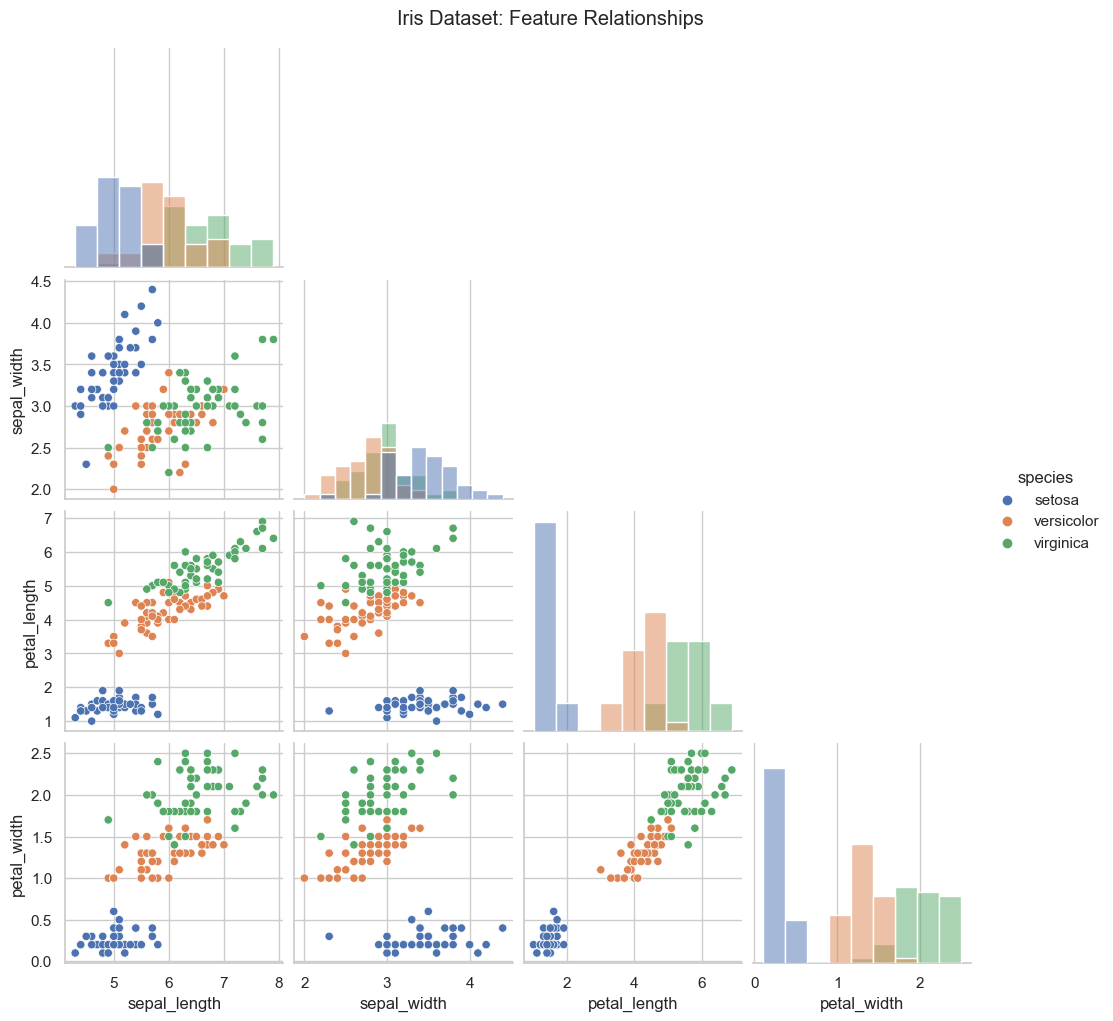

C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\Admin\AppData\Roaming\Python\Python311\sit

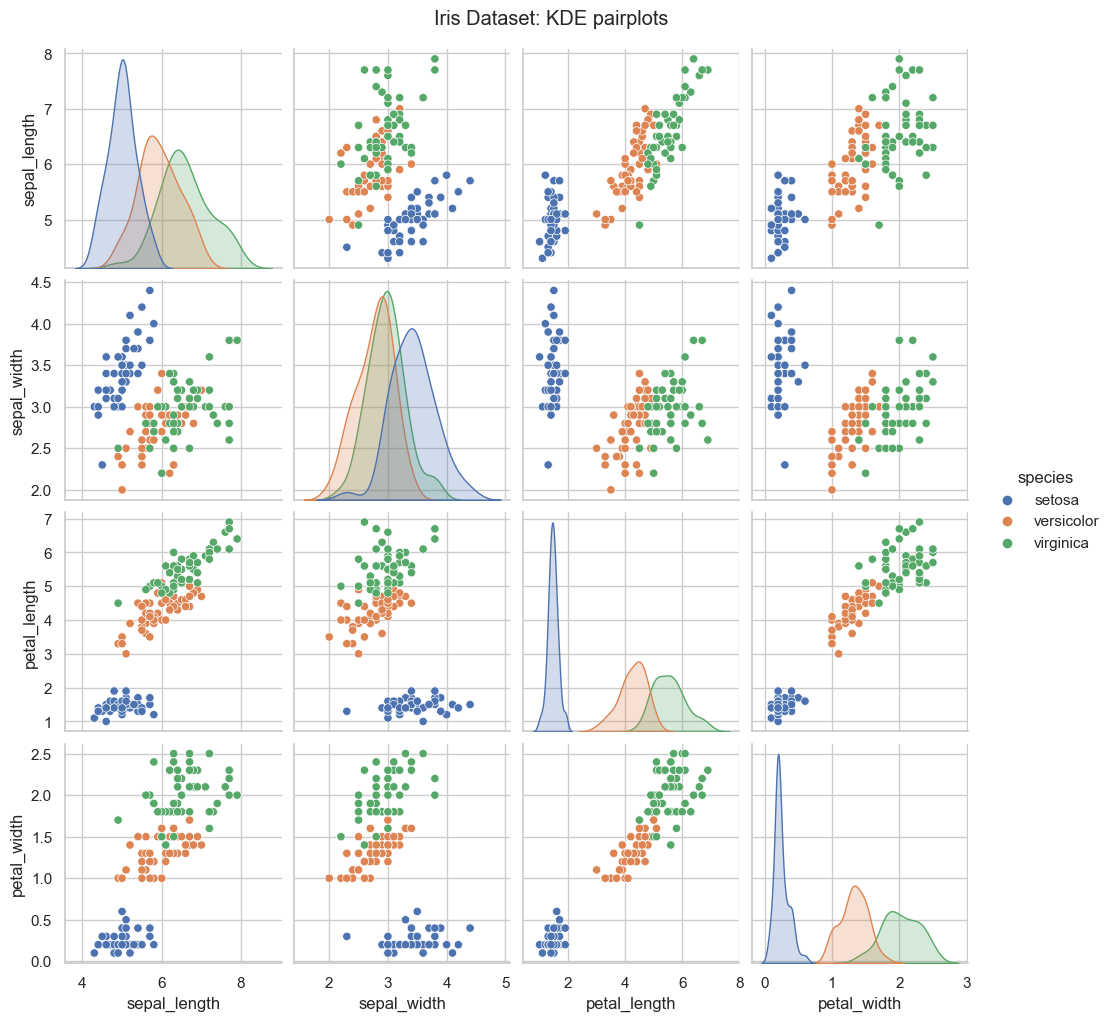

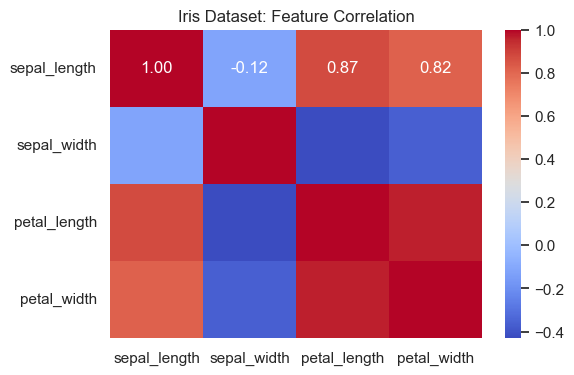

In [5]:
sns.pairplot(
    df, hue="species", diag_kind="hist", corner=True
)
plt.suptitle("Iris Dataset: Feature Relationships", y=1.02)
plt.show()

sns.pairplot(
    df, hue="species", diag_kind="kde"
)
plt.suptitle("Iris Dataset: KDE pairplots", y=1.02)
plt.show()

plt.figure(figsize=(6,4))
sns.heatmap(df.drop(columns='species').corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Iris Dataset: Feature Correlation")
plt.show()

In [6]:
X = df.drop(columns=["species"])
y = df["species"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())
display(y.head())

le = LabelEncoder()
y_enc = le.fit_transform(y)
class_names = le.classes_
print("\nEncoded classes:" , class_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=RandomState, stratify=y_enc
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(le.inverse_transform(y_train).tolist())
print(__import__("pandas").Series(
    le.inverse_transform(y_train)
).value_counts())

print("\nTesting class distribution:")
print(__import__("pandas").Series(
    le.inverse_transform(y_test)
).value_counts())

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Features Shape: (150, 4)
Target Shape: (150,)


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


Encoded classes: ['setosa' 'versicolor' 'virginica']

Training samples: 120
Testing samples: 30

Training class distribution:
['setosa', 'virginica', 'versicolor', 'setosa', 'versicolor', 'virginica', 'versicolor', 'virginica', 'virginica', 'virginica', 'virginica', 'versicolor', 'versicolor', 'versicolor', 'versicolor', 'setosa', 'setosa', 'virginica', 'virginica', 'setosa', 'versicolor', 'setosa', 'virginica', 'setosa', 'versicolor', 'virginica', 'virginica', 'setosa', 'virginica', 'setosa', 'setosa', 'versicolor', 'versicolor', 'setosa', 'virginica', 'virginica', 'versicolor', 'versicolor', 'virginica', 'versicolor', 'setosa', 'versicolor', 'setosa', 'virginica', 'setosa', 'setosa', 'virginica', 'setosa', 'setosa', 'setosa', 'setosa', 'versicolor', 'virginica', 'versicolor', 'setosa', 'virginica', 'versicolor', 'virginica', 'setosa', 'virginica', 'setosa', 'versicolor', 'virginica', 'setosa', 'versicolor', 'versicolor', 'virginica', 'versicolor', 'versicolor', 'virginica', 'setosa'

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Original Training Data:\n", X_train.head())
print("\nScaled Training Data:\n", pd.DataFrame(X_train_scaled, columns=X_train.columns).head())

Original Training Data:
      sepal_length  sepal_width  petal_length  petal_width
8             4.4          2.9           1.4          0.2
106           4.9          2.5           4.5          1.7
76            6.8          2.8           4.8          1.4
9             4.9          3.1           1.5          0.1
89            5.5          2.5           4.0          1.3

Scaled Training Data:
    sepal_length  sepal_width  petal_length  petal_width
0     -1.721568    -0.332101     -1.345722    -1.323276
1     -1.124492    -1.227655      0.414505     0.651763
2      1.144395    -0.555990      0.584850     0.256755
3     -1.124492     0.115676     -1.288941    -1.454945
4     -0.408002    -1.227655      0.130598     0.125086


In [8]:
logistic_model = LogisticRegression(
    max_iter=1000, random_state=RandomState
)
logistic_model.fit(X_train_scaled, y_train)
print("LogisticRegression model trained successfully.")

tree_model = DecisionTreeClassifier(
    max_depth=5, random_state=RandomState
)
tree_model.fit(X_train_scaled, y_train)
print("DecisionTreeClassifier model trained successfully.")

y_pred_logistic = logistic_model.predict(X_test_scaled)
y_pred_tree = tree_model.predict(X_test_scaled)
print("Logistic Regression Predictions:\n", y_pred_logistic)
print("\nDecision Tree Predictions:\n", y_pred_tree)

LogisticRegression model trained successfully.
DecisionTreeClassifier model trained successfully.
Logistic Regression Predictions:
 [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

Decision Tree Predictions:
 [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [9]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model
}
results = []
preds = {}

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)
    preds[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average='macro', zero_division=0),
        "F1 Score (Macro)": f1_score(y_test, y_pred, average='macro', zero_division=0),
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.style.format("{:.4f}"))

for name, y_pred in preds.items():
    print(f"\n{'='*60}")
    print(f"{name.upper()} Classification Report:")
    print("="*60)

    print(classification_report(
        y_test, y_pred,
        labels=[0, 1, 2], 
        target_names=class_names, 
        zero_division=0
        ))

,Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333



LOGISTIC REGRESSION Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


DECISION TREE Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



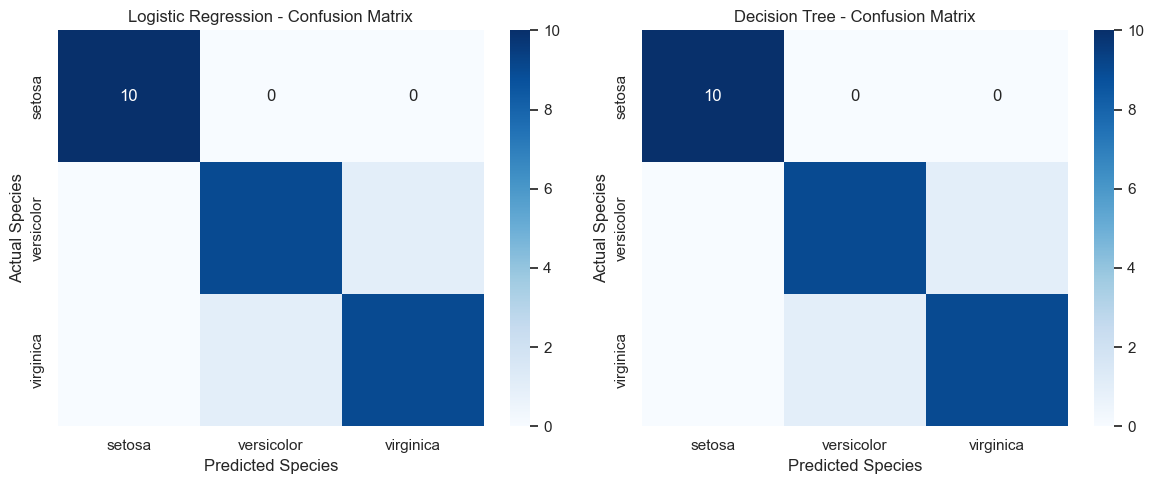

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Logistic Regression", logistic_model),
    ("Decision Tree", tree_model)
]

for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(
        y_test, y_pred, labels=logistic_model.classes_)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names,
        ax=ax
    )

    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

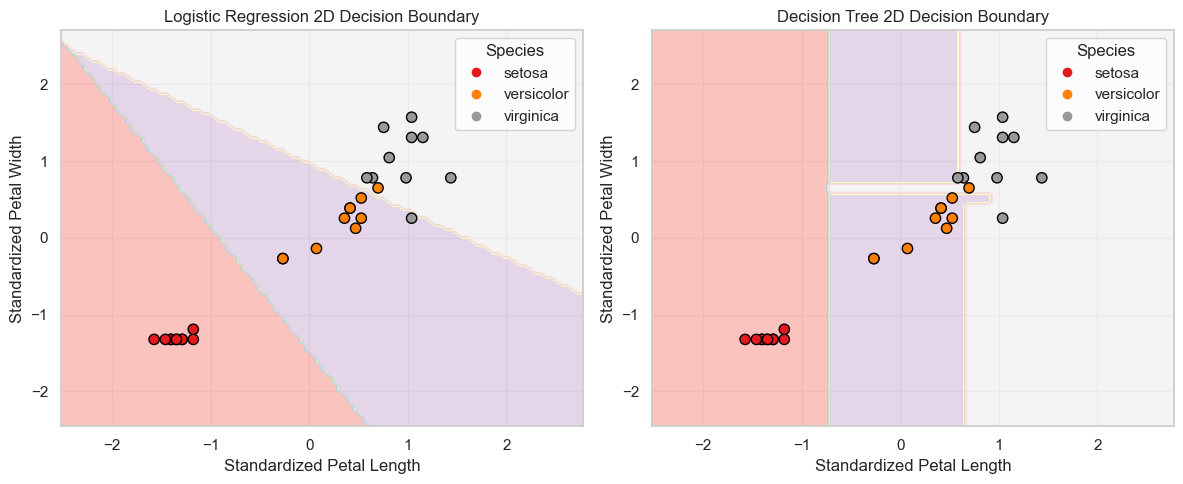

In [ ]:
feature_2d = ["petal_length", "petal_width"]

X2_train_raw = X_train[feature_2d]
X2_test_raw = X_test[feature_2d]

scaler_2d = StandardScaler()
X2_train_scaled = scaler_2d.fit_transform(X2_train_raw)
X2_test_scaled = scaler_2d.transform(X2_test_raw)

logistic_2d = LogisticRegression(
    max_iter=1000, random_state=RandomState
)
logistic_2d.fit(X2_train_scaled, y_train)

tree_2d = DecisionTreeClassifier(
    max_depth=5, random_state=RandomState
)
tree_2d.fit(X2_train_scaled, y_train)

models_2d = [
    ("Logistic Regression", logistic_2d),
    ("Decision Tree", tree_2d)
]

fig, axes = plt.subplots(1 , 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models_2d):

    DecisionBoundaryDisplay.from_estimator(
        model, X2_train_scaled, response_method="predict", cmap="Pastel1",ax=ax, alpha=0.8
    )

    scatter = ax.scatter(
        X2_test_scaled[:, 0],
        X2_test_scaled[:, 1],
        c=y_test,
        cmap="Set1",
        edgecolor="black",
        s=55
    )
    ax.set_title(f"{name} 2D Decision Boundary")
    ax.set_xlabel("Standardized Petal Length")
    ax.set_ylabel("Standardized Petal Width")

    ax.legend(
        handles=scatter.legend_elements()[0],
        labels=list(class_names),
        title="Species"
    )

plt.tight_layout()
plt.savefig("decision_boundaries.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
best_score = results_df["F1 Score (Macro)"].max()

best_models = results_df.index[
    np.isclose(
        results_df["F1 Score (Macro)"], best_score)
].tolist()

if len(best_models) == len(results_df):
    print("\nBoth models achieved the same best F1 Score (Macro).")
else:
    print("\nBest Model(s) Based on F1 Score (Macro):", best_models)

print("\nBenchmark results:\n", results_df)


Both models achieved the same best F1 Score (Macro).

Benchmark results:
                      Accuracy  Precision (Macro)  Recall (Macro)  \
Model                                                              
Logistic Regression  0.933333           0.933333        0.933333   
Decision Tree        0.933333           0.933333        0.933333   

                     F1 Score (Macro)  
Model                                  
Logistic Regression          0.933333  
Decision Tree                0.933333  


## Conclusion

In this project, I implemented an end-to-end multi-class classification pipeline using the Iris dataset and Scikit-Learn.

I performed exploratory data analysis using Seaborn, split the dataset into training and testing sets using an 80/20 ratio, and standardized the features using StandardScaler.

I trained Logistic Regression and Decision Tree classifiers and evaluated them using accuracy, macro precision, macro recall, macro F1-score, classification reports, and confusion matrices.

Both models achieved 93.33% test accuracy in my experiment. Therefore, they tied on accuracy, and I compared their precision, recall, and F1-score to examine their class-wise performance further.

I also visualized the decision boundaries using petal length and petal width.

This project demonstrates the complete workflow of preparing data, training classification models, evaluating predictions, and visualizing machine-learning results.